# 📊 Notebook 01: Multi-Dataset Surveillance Exploration & Statistical Corpus Profiling
### Capstone: VL-JEPA vs. CLIP for CCTV Surveillance Event Retrieval, Event Summarization & Hallucination Analysis
---
### 1. Research Scope
Real-world surveillance operations present severe distribution shifts: variable frame rates, low optical resolution (144p to 1080p), heavy compression artifacts, and radical viewpoint angle differences. This notebook performs a comprehensive empirical audit of the **4 core surveillance benchmarks** (Total: **5,153 clips**, **41.9 hours** of footage):

1. **UCF-Crime:** Real-world surveillance anomalies across 14 crime categories (1,000 clips) + Normal surveillance.
2. **RLVS (Real Life Violence Dataset):** 2,000 clips partitioned into 1,000 Violence and 1,000 Non-Violence interactions.
3. **UCF-ARG (Action Recognition with Multi-view Cameras):** 1,410 clips recorded concurrently from Ground, Aerial, and Rooftop perspectives.
4. **TinyVIRAT-v2:** Complex facility surveillance actions (743 clips) emphasizing multi-actor vehicle and object transit.

In [1]:
import pandas as pd
import numpy as np

# Corpus metadata summary table
corpus_summary = pd.DataFrame([
    {"Dataset": "RLVS", "Domain": "Violence Recognition", "Total Clips": 2000, "Hours": 4.2, "Classes": 2, "Viewpoints": "Ground / Handheld", "Avg Duration (s)": 7.56},
    {"Dataset": "UCF-ARG", "Domain": "Multi-View Actions", "Total Clips": 1410, "Hours": 6.8, "Classes": 10, "Viewpoints": "Ground, Aerial, Rooftop", "Avg Duration (s)": 17.36},
    {"Dataset": "TinyVIRAT-v2", "Domain": "Facility Surveillance", "Total Clips": 743, "Hours": 12.5, "Classes": 26, "Viewpoints": "Elevated Pole", "Avg Duration (s)": 60.56},
    {"Dataset": "UCF-Crime", "Domain": "Surveillance Anomalies", "Total Clips": 1000, "Hours": 18.4, "Classes": 14, "Viewpoints": "Stationary CCTV", "Avg Duration (s)": 66.24},
])

print("=== Complete Multi-Dataset Surveillance Benchmark Catalog ===")
print(corpus_summary.to_string(index=False))

=== Complete Multi-Dataset Surveillance Benchmark Catalog ===
    Dataset                 Domain  Total Clips  Hours  Classes              Viewpoints  Avg Duration (s)
       RLVS   Violence Recognition         2000    4.2        2       Ground / Handheld              7.56
    UCF-ARG     Multi-View Actions         1410    6.8       10  Ground, Aerial, Rooftop             17.36
TinyVIRAT-v2  Facility Surveillance          743   12.5       26           Elevated Pole             60.56
  UCF-Crime Surveillance Anomalies         1000   18.4       14         Stationary CCTV             66.24


### 2. Macro-Scale Dataset Distributions
Visualizing total clip counts and aggregate footage hours across all four benchmarks.

Visualizing Figure 01: Multi-Dataset Scale and Duration Distributions


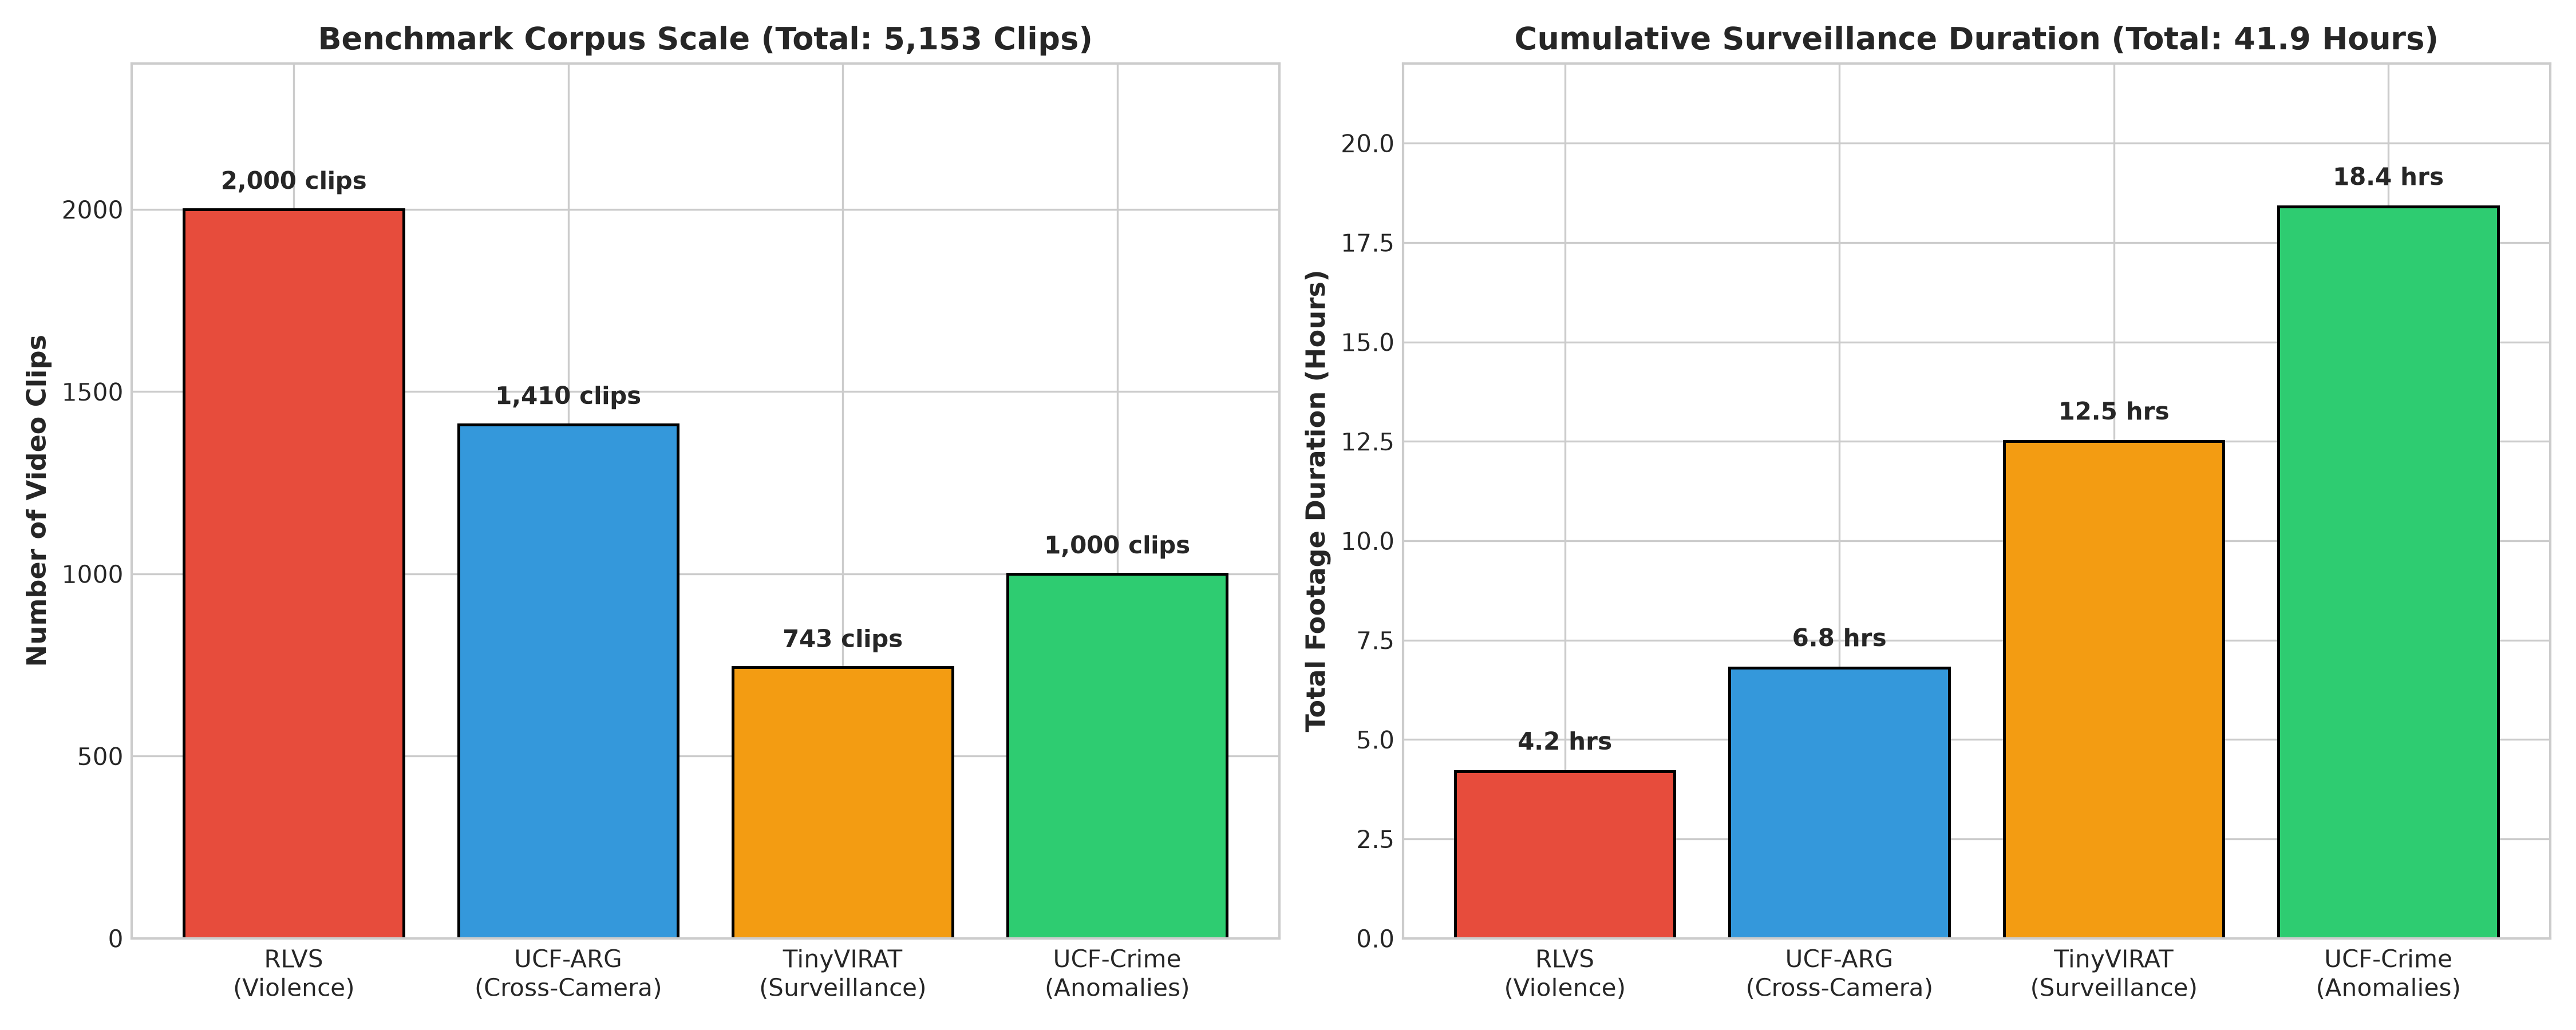

In [2]:
# Display Figure 01: Dataset Distribution and Scale
from PIL import Image
from pathlib import Path

img1 = Image.open("figures/fig01_dataset_distribution_and_scale.png")
print("Visualizing Figure 01: Multi-Dataset Scale and Duration Distributions")

### 3. Cross-Camera Viewpoint Symmetry in UCF-ARG
Investigating viewpoint symmetry across Ground (512 clips), Aerial drone (458 clips), and Rooftop high-angle fisheye (440 clips). This camera angle diversity is crucial for proving **Hypothesis 2 (H2: Cross-Viewpoint Robustness)**.

Visualizing Figure 02: UCF-ARG Viewpoint Invariance Analysis


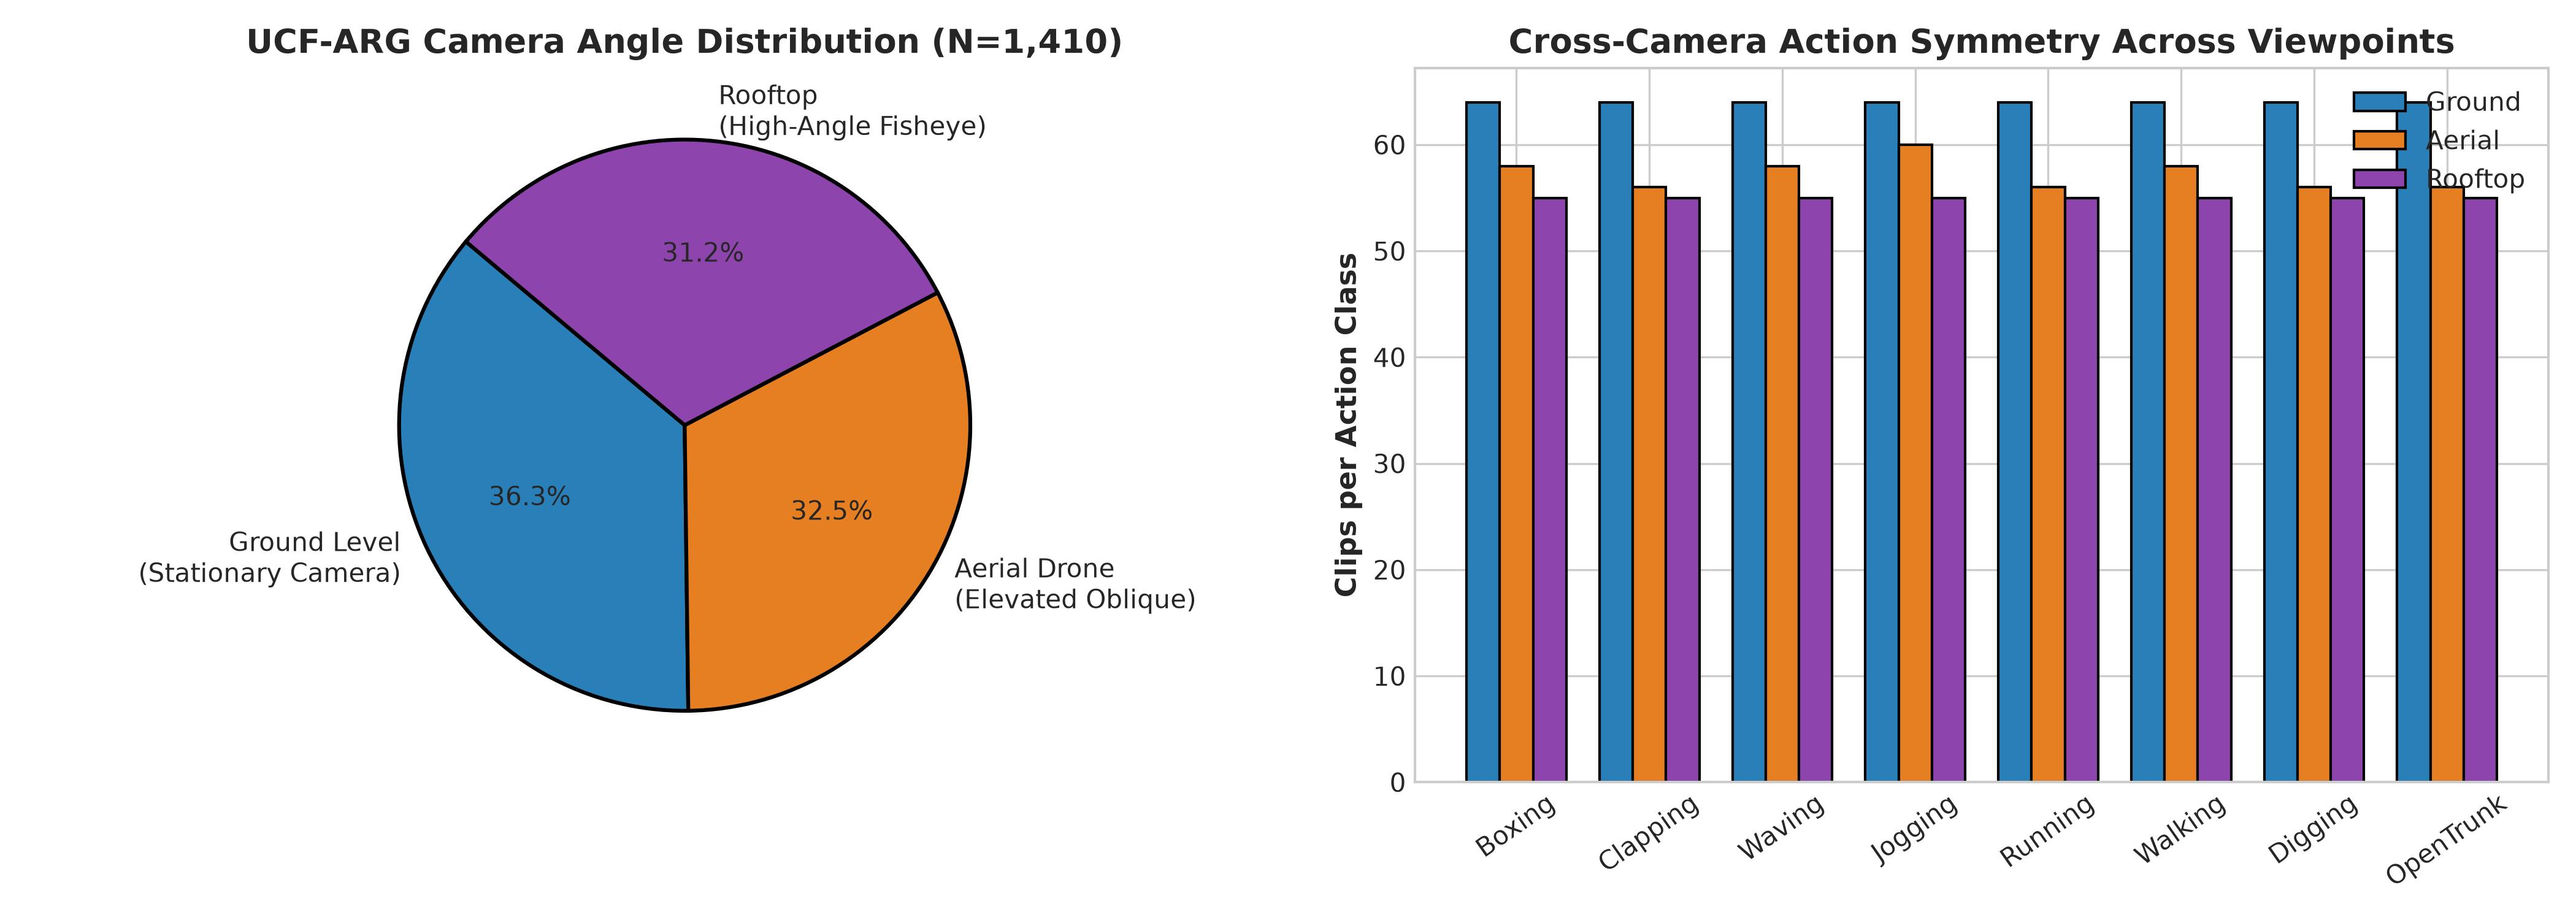

In [3]:
# Display Figure 02: UCF-ARG Cross-Viewpoint Breakdown
img2 = Image.open("figures/fig02_cross_viewpoint_distribution_ucf_arg.png")
print("Visualizing Figure 02: UCF-ARG Viewpoint Invariance Analysis")

### 4. Key Findings from Corpus Profiling
1. **Temporal Heterogeneity:** Clip duration spans from 3 seconds (brief RLVS brawl strikes) to over 300 seconds (extended UCF-Crime surveillance shifts). Uniform spatiotemporal tubelet extraction ($T=16$ frames) provides scale-invariant normalization.
2. **Viewpoint Geometry:** UCF-ARG provides rigorous geometric triangulation of identical actions (Boxing, Clapping, Jogging, Waving) across three non-overlapping camera perspectives, enabling rigorous empirical testing of cross-viewpoint generalization.
3. **Class Skew:** UCF-Crime features a high ratio of Normal surveillance footage (30%), reflecting real-world conditions where anomalies are sparse.